# [16.17] One Query, Many Interactions

# Introduction

Today you'll build two algorithms that estimate feature interactions without asking a model
about every possible feature subset. Your first algorithm will turn **one model response into an
update for every pair**. Your second will fit a sequence of weighted regressions to the same
responses. You'll be able to see what each query buys you, where sampling noise enters, and when
the regression has too little information to identify an answer.

The central question is simple: **how accurately can we estimate every pair interaction when we can query only some coalitions?**

We will use exact small games to understand the algorithms, then repeat the comparison on eight-feature Concrete-strength predictors. Eight features are small enough to enumerate all 256 coalitions for a reference. The sampled estimators will receive only their requested values. Keeping the exact answer outside the estimator lets us measure an error that would normally be unknown.

This lesson continues 16.3's Shapley Interaction Index (SII). Both algorithms target the **same SII**. Shapley-Taylor and Faith-Shap from 16.16 choose different allocations; disagreement between those definitions is a different issue from the estimation error studied here.

## Content & Learning Objectives

### 1️⃣ Share one query across many interactions

You'll rewrite the four-term pair derivative as a weighted sum over a common set of coalitions. This is the step that lets SHAP-IQ reuse each model evaluation for all pairs.

> ##### Learning Objectives
>
> - Distinguish a coalition, a context and an interaction set.
> - Derive the sign and magnitude of a shared-query update.
> - See why one apparently large update can cancel in the complete answer.

### 2️⃣ Sample a game, measure the uncertainty

You'll implement a size-then-subset sampler and the SHAP-IQ mean and standard error. The same random draw can occur more than once: it costs one cached model query but still contributes multiple times to the Monte Carlo average.

> ##### Learning Objectives
>
> - Separate a size probability from a per-coalition probability.
> - Implement importance weighting and an iid standard error.
> - Count draw requests and unique queries correctly.

### 3️⃣ Fit the pairwise KernelSHAP-IQ limit

You'll solve a constrained least-squares problem, then use it to fit main effects and pair residuals. The interesting part is the boundary: infinite weight does not mean every boundary residual can be made zero.

> ##### Learning Objectives
>
> - Separate the feasible particular solution from free directions.
> - Derive the pair design and boundary least-squares constraint.
> - Detect rank deficiency rather than silently regularizing it away.

### 4️⃣ Read the real-model comparison

You'll apply both estimators to every held-out recipe for seven known predictors, compare against exact SII, and inspect two editable experiments.

> ##### Learning Objectives
>
> - Read signed errors alongside query-budget curves and model controls.
> - Compare estimated SE with the exact sampling variance of a finite game.
> - Explain the limits of a precomputed-oracle query benchmark.

The eight exercises should take about 90–120 minutes, followed by 30–45 minutes for the model comparison and plays. If the nullspace derivation is unfamiliar, work through its three-coefficient example and use the solution to continue; return to the proof once the end-to-end result is clear.

## Setup

All methods use CPU float64. An integer mask contains feature `i` exactly when bit `i` is set. Pair columns follow lexicographic feature order: `(0,1), (0,2), ...`. We supply input validation, indexing helpers and plotting. The sampling and estimation algorithms will be your own functions.

In [1]:
from __future__ import annotations
import itertools
import math
import os
import sys
from collections.abc import Callable
from pathlib import Path
from types import SimpleNamespace
from typing import Any

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch as t
from torch import Tensor
from IPython.display import display

chapter = "chapter16_shapley_attribution_baselines"
root_dir = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / chapter).exists())
if str(root_dir) not in sys.path:
    sys.path.insert(0, str(root_dir))
from chapter16_shapley_attribution_baselines.exercises.part17_shapiq_estimators import (
    estimator_methods_tests as tests, estimator_study as study, estimator_plots as plots,
)
from chapter16_shapley_attribution_baselines.exercises.part17_shapiq_estimators.estimator_methods import (
    _players, _masks, _values, _queried_inputs, interaction_masks, boundary_masks,
)
t.set_num_threads(4)
OUTPUT_DIR = Path(os.environ.get("ARENA_ESTIMATOR_OUTPUT_DIRECTORY", "./estimator_outputs"))
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

def show_figure(figure, name):
    figure.savefig(OUTPUT_DIR / f"{name}.png", dpi=130, bbox_inches="tight")
    display(figure)
    plt.close(figure)

## Cold open: one coalition says something about six pairs

Return to the controlled score from 16.3. Two weak individual features have a strong joint effect, and a triple contributes additional pairwise credit:

$$v(x)=0.2x_0+0.2x_1+5x_2+4x_3+3x_0x_1+2x_0x_1x_2.$$

Suppose you query only coalition `{0,1}`. Its value is `3.4`. Can that single response tell you the interaction of the entirely absent pair `{2,3}`?

<details>
<summary>Predict before continuing</summary>

It cannot identify that pair by itself. It can contribute one signed term to an estimator of that pair. Other queries must cancel contributions due to unrelated features. The complete SII of `{2,3}` is zero, even though this query contributes positively to its shared-query sum.

</details>

In [2]:
# This explicit sixteen-row polynomial is our known exact teaching game.
game_rows = []
for mask in range(16):
    a, b, c, d = [float(bool(mask & (1 << i))) for i in range(4)]
    value = .2*a + .2*b + 5*c + 4*d + 3*a*b + 2*a*b*c
    game_rows.append({"mask": f"{mask:04b}", "A": a, "B": b, "C": c, "D": d, "value": value})
display(pd.DataFrame(game_rows).set_index("mask"))
print("Query {A,B}:", game_rows[3]["value"])

,A,B,C,D,value
mask,,,,,
0000,0.0,0.0,0.0,0.0,0.0
0001,1.0,0.0,0.0,0.0,0.2
0010,0.0,1.0,0.0,0.0,0.2
0011,1.0,1.0,0.0,0.0,3.4
0100,0.0,0.0,1.0,0.0,5.0
0101,1.0,0.0,1.0,0.0,5.2
0110,0.0,1.0,1.0,0.0,5.2
0111,1.0,1.0,1.0,0.0,10.4
1000,0.0,0.0,0.0,1.0,4.0


Query {A,B}: 3.4


# 1️⃣ Share one query across many interactions

## Turn masks into model inputs

Our algorithms use a matrix $Z$ with one queried coalition per row and one feature per column. Its entries are zero or one. For four features, mask `6` is binary `0110`, so its row is `[0,1,1,0]`. The printed binary string puts the most significant bit first; the feature columns put feature zero first. Keep these conventions distinct.

### Exercise - implement `coalition_design`

> ```yaml
> Difficulty: 🔴⚪⚪⚪⚪
> Importance: 🔵🔵🔵⚪⚪
>
> You should spend up to 5 minutes on this exercise.
> ```

Use a vector of feature bits and a broadcast bitwise AND. Preserve repeated input masks and their order.

In [3]:
def coalition_design(masks: Tensor, *, n_players: int) -> Tensor:
    """Return X[queried coalition, feature] in float64."""
    n = _players(n_players)
    _masks(masks, n)
    bits = 1 << t.arange(n, dtype=t.int64)
    return masks[:, None].bitwise_and(bits).ne(0).to(t.float64)

tests.test_coalition_design(fn=coalition_design)

All tests in test_coalition_design passed!


<details>
<summary>Expected output</summary>

`[0,1,6,15]` maps to the empty row, feature zero, features one and two, and the full row. The focused test prints `All tests in test_coalition_design passed!`.

</details>

<details>
<summary>Help - which axis should be broadcast?</summary>

Compare `masks[:, None]` with `1 << torch.arange(n_players)`. Convert the nonzero result to float64 after the bitwise operation.

</details>

## Rearrange the pair derivative

For a fixed pair $S=\{i,j\}$ and a disjoint context $C$, the second difference is

$$\Delta_S v(C)=v(C\cup S)-v(C\cup\{i\})-v(C\cup\{j\})+v(C).$$

SII averages this derivative with weight

$$m_s(c)=\frac{1}{(n-s+1)\binom{n-s}{c}}.$$

For pairs, $s=2$. Equivalently, the size of the context is uniform over `0..n-2`, then the context is uniform within that size. The direct definition asks about different contexts for each pair. To share queries, expand every derivative and collect the coefficient of the **same queried coalition** $T$.

If $k=\lvert T\cap S\rvert$, the context behind this occurrence must be $C=T\setminus S$. The derivative contributes sign $(-1)^{s-k}$ and context size $\lvert T\rvert-k$. Therefore

$$I^{\mathrm{SII}}(S)=\sum_{T\subseteq N}v_0(T)\,\gamma_s(T,S),\qquad
\gamma_s(T,S)=\frac{(-1)^{s-\lvert T\cap S\rvert}}{(n-s+1)\binom{n-s}{\lvert T\rvert-\lvert T\cap S\rvert}},$$

where $v_0(T)=v(T)-v(\varnothing)$. This is SHAP-IQ's shared-evaluation representation. The model query is independent of the pair; only its weight changes.

### Exercise - implement `sii_query_weights`

> ```yaml
> Difficulty: 🔴🔴🔴⚪⚪
> Importance: 🔵🔵🔵🔵🔵
>
> You should spend up to 15 minutes on this exercise.
> ```

Return one gamma row for each query and one column for each interaction of the requested order. The supplied `interaction_masks` enumerates the interaction columns, not the power set of model queries. Compute overlap sizes using the two binary designs; use the formula above for sign and denominator.

In [4]:
def sii_query_weights(masks: Tensor, *, n_players: int, order: int = 2) -> Tensor:
    """The SHAP-IQ gamma coefficient of each queried value in every order-s SII.

    If k=|T intersection S|, gamma(T,S)=(-1)**(s-k) /
    ((n-s+1) * choose(n-s, |T|-k)). No model evaluations occur here.
    """
    n = _players(n_players)
    terms = interaction_masks(n, order)
    design = coalition_design(masks, n_players=n)
    term_design = coalition_design(terms, n_players=n)
    overlap = (design @ term_design.T).to(t.int64)
    outside = design.sum(-1).to(t.int64)[:, None] - overlap
    denominator = t.tensor([(n - order + 1) * math.comb(n - order, r) for r in range(n - order + 1)], dtype=t.float64)
    sign = t.where((order - overlap) % 2 == 0, 1.0, -1.0).to(t.float64)
    return sign / denominator[outside]

tests.test_sii_query_weights(fn=sii_query_weights)

All tests in test_sii_query_weights passed!


<details>
<summary>Expected output</summary>

For `n_players=4`, query `{0,1}` and pair order, the gamma row is

`[1/3, -1/6, -1/6, -1/6, -1/6, 1/3]`.

For example, pair `{0,2}` overlaps once, so its sign is negative and its context contains one of the other two players. The complete additive game returns zero in every pair column.

</details>

<details>
<summary>Help - avoid one Python loop per query and pair</summary>

If `Z` contains query designs and `A` contains interaction designs, `Z @ A.T` gives every overlap size. Subtract from each query's population count. Precompute the short denominator vector for context sizes `0..n-order` and index it with that result.

</details>

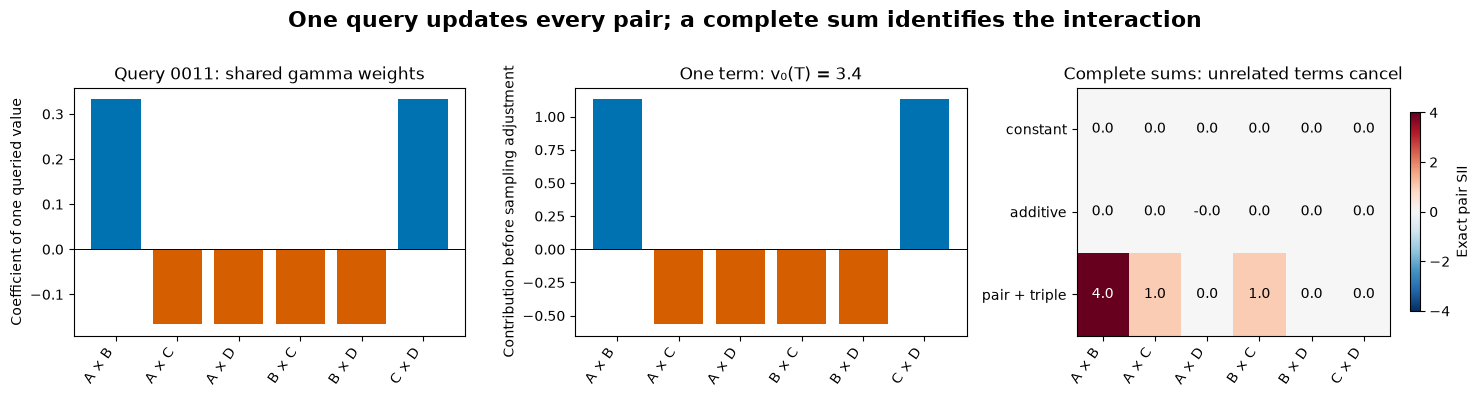

In [5]:
games = plots.analytic_games(coalition_design)
figure = plots.plot_shared_query(games, sii_query_weights, query_mask=3)
show_figure(figure, "01_shared_query")

<details>
<summary>Interpretation - why does the absent pair receive a positive update?</summary>

The update is a term in an algebraic sum, not a claim that the absent pair caused the response. The plot shows the complete additive control canceling after all coalitions are included. At finite sampling budgets the cancellation is imperfect. A large contribution from one query should never be read as a recovered interaction by itself.

</details>

## Try It Yourself: follow one query

Change the coalition mask below. Predict which pair columns become negative before running it. Then remove the interaction terms while retaining the additive weights.

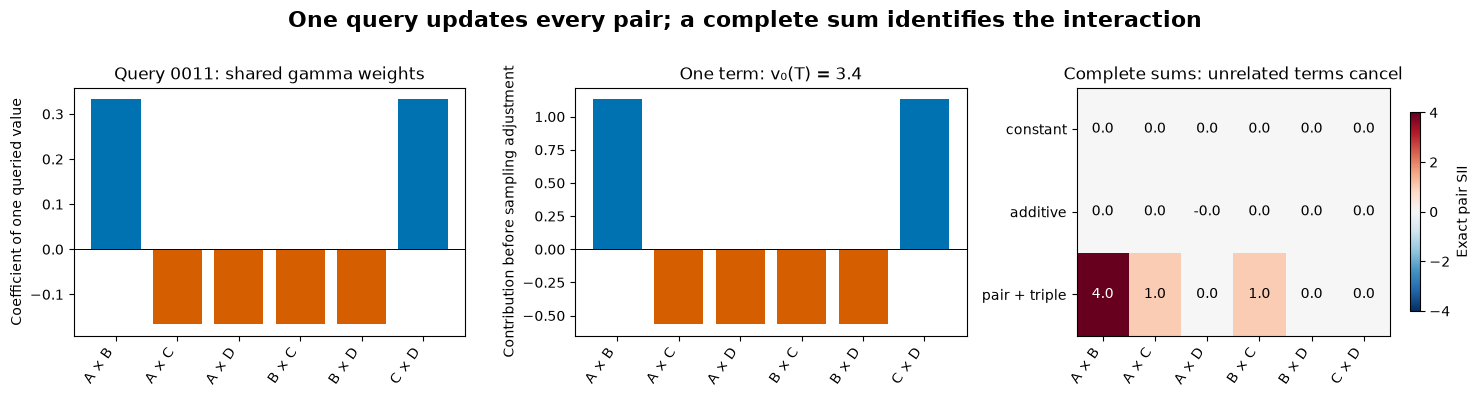

In [6]:
QUERY_MASK = 3           # integer mask 0..15
GAME_NAME = "mixed"      # "mixed", "additive", "constant", or "pure_four"
figure = plots.plot_shared_query(games, sii_query_weights, query_mask=QUERY_MASK, game_name=GAME_NAME)
show_figure(figure, "02_query_play")

# 2️⃣ Sample a game, measure the uncertainty

## Query the boundary exactly

We will query the empty and full sets, every singleton and every singleton complement. For eight features, these are 18 unique coalitions. Sample the remaining 238 coalitions with replacement.

This is a fixed teaching design, not an outcome-driven choice of strata. The exact boundary is useful for both estimators and lets them share the same requested values. A query cache will eliminate duplicate model calls while preserving duplicate samples in the averages.

## A size is not a coalition

Let $p_k$ be the probability of drawing size $k$. After choosing a uniformly random set of that size, its probability is

$$p(T)=\frac{p_{\lvert T\rvert}}{\binom{n}{\lvert T\rvert}}.$$

The kernel proposal uses a per-coalition weight proportional to $1/\binom{n-2}{k-1}$. Multiplying by the number of coalitions of that size gives size mass proportional to $1/[k(n-k)]$. Uniform sampling over *coalitions* instead gives size mass proportional to $\binom{n}{k}$. Both distributions are restricted to sizes `2..n-2` here.

### Exercise - implement `sample_coalitions`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵🔵
>
> You should spend up to 12 minutes on this exercise.
> ```

Create a local seeded generator. Draw a size from the appropriate distribution, generate a uniform random feature permutation, and retain its first `size` elements. Return the mask and its **per-coalition probability** for every draw. Do not enumerate all `2**n_players` masks.

In [7]:
def sample_coalitions(
    *, n_players: int, draws: int, seed: int, proposal: str = "kernel"
) -> tuple[Tensor, Tensor]:
    """Draw iid interior coalitions, retaining duplicate draws and per-set p(T).

    Draw size first, then a uniformly random subset of that size. Kernel means
    p(T) proportional to 1/choose(n-2, |T|-1), restricted to 2..n-2.
    Uniform means uniform over individual sets in that same support.
    """
    n = _players(n_players)
    if type(draws) is not int or draws < 2 or type(seed) is not int or seed < 0:
        raise ValueError("draws >= 2 and a nonnegative integer seed are required.")
    if proposal not in ("kernel", "uniform"):
        raise ValueError("proposal must be 'kernel' or 'uniform'.")
    sizes = t.arange(2, n - 1, dtype=t.int64)
    if proposal == "kernel":
        size_mass = 1.0 / (sizes.to(t.float64) * (n - sizes))
    else:
        size_mass = t.tensor([math.comb(n, int(k)) for k in sizes], dtype=t.float64)
    size_probability = size_mass / size_mass.sum()
    generator = t.Generator(device="cpu").manual_seed(seed)
    chosen = t.multinomial(size_probability, draws, replacement=True, generator=generator)
    selected_sizes = sizes[chosen]
    # Each row's random permutation gives a uniform subset, without 2**n storage.
    permutations = t.rand((draws, n), generator=generator, dtype=t.float64).argsort(dim=-1)
    take = t.arange(n)[None, :] < selected_sizes[:, None]
    masks = ((1 << permutations) * take).sum(-1)
    combinations = t.tensor([math.comb(n, int(k)) for k in sizes], dtype=t.float64)
    probabilities = (size_probability / combinations)[chosen]
    return masks, probabilities

tests.test_sample_coalitions(fn=sample_coalitions)

All tests in test_sample_coalitions passed!


<details>
<summary>Expected output</summary>

Repeated calls with the same seed return the same masks and probabilities; the global Torch RNG is unchanged. For eight features, each uniform interior coalition has probability `1/238`. Kernel sampling gives equal probabilities to sets of the same size, with larger per-set mass near the support boundaries.

</details>

<details>
<summary>Help - make a random subset without a power-set table</summary>

Draw a `[draws, n_players]` matrix of independent continuous random scores and argsort each row. Its first `k` feature indices form a uniform size-`k` subset. Sum their bit values to make the integer mask. Divide the selected size probability by `math.comb(n_players, k)`.

</details>

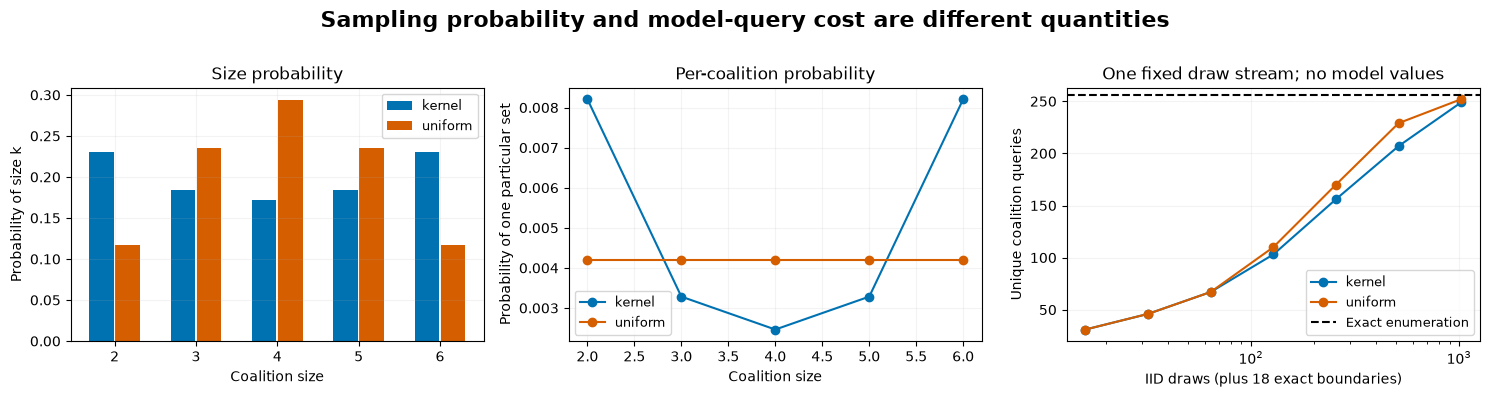

In [8]:
figure = plots.plot_sampling(sample_coalitions)
show_figure(figure, "03_sampling_and_cost")

## SHAP-IQ is an importance-weighted mean

Let $B$ be the exact boundary. Its contribution is

$$c_B(S)=\sum_{T\in B}v_0(T)\gamma_s(T,S).$$

For an interior draw $T_r\sim p$, define $Y_r(S)=v_0(T_r)\gamma_s(T_r,S)/p(T_r)$. Then

$$\widehat I(S)=c_B(S)+\frac1K\sum_{r=1}^{K}Y_r(S),\qquad
\widehat{\mathrm{SE}}(S)=\sqrt{\frac{1}{K(K-1)}\sum_{r=1}^{K}\big(Y_r(S)-\overline Y(S)\big)^2}.$$

The mean is unbiased for the fixed finite game under iid sampling. The SE estimates sampling variability conditional on that game. It says nothing about uncertainty in the training data, fitted model or choice of donor background. A normal error band can still have poor coverage at a small budget.

### Exercise - implement `shapiq_estimate`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵🔵
>
> You should spend up to 12 minutes on this exercise.
> ```

The first boundary value is the empty coalition. Center both boundary and sampled values by it. Compute the exact boundary sum and the mean of the weighted sampled contributions. Return the estimate and the sample standard error. Support arbitrary leading game axes.

In [9]:
def shapiq_estimate(
    boundary_values: Tensor,
    sampled_values: Tensor,
    sampled_masks: Tensor,
    probabilities: Tensor,
    *, n_players: int, order: int = 2,
) -> tuple[Tensor, Tensor]:
    """Return the SHAP-IQ point estimate and iid sample standard error.

    The first boundary is empty. Subtract its value from every queried value:
    this preserves offset invariance for each realized sample, not just in mean.
    SE concerns iid draws from a fixed game, not uncertainty about the model/data.
    """
    n = _players(n_players)
    edges = _queried_inputs(boundary_values, sampled_values, sampled_masks, probabilities, n)
    baseline = boundary_values[..., :1]
    exact = (boundary_values - baseline) @ sii_query_weights(edges, n_players=n, order=order)
    weights = sii_query_weights(sampled_masks, n_players=n, order=order) / probabilities[:, None]
    contributions = (sampled_values - baseline)[..., :, None] * weights
    estimate = exact + contributions.mean(dim=-2)
    standard_error = (contributions.var(dim=-2, correction=1) / len(sampled_masks)).sqrt()
    return estimate, standard_error

tests.test_shapiq_estimate(fn=shapiq_estimate)

All tests in test_shapiq_estimate passed!


<details>
<summary>Expected output</summary>

Summing a complete uniformly enumerated interior recovers exact SII. A repeated sample retains its multiplicity. Adding a constant to every game value changes neither the estimate nor its SE. An additive game's finite-sample pair estimate can be nonzero, while a constant game is exactly zero after centering.

</details>

<details>
<summary>Help - which variance correction do I need?</summary>

Use sample variance with denominator `K-1`, then divide by `K` before taking the square root. The exact boundary contributes no sampling variance. Do not deduplicate the array of contributions and do not divide by the number of unique queried coalitions.

</details>

## Count what you actually asked the model

### Exercise - implement `query_sampled_game`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
>
> You should spend up to 10 minutes on this exercise.
> ```

Concatenate boundary and sampled masks, query each unique mask once, then use an inverse index to reconstruct the original requested order. Return the boundary values, repeated sampled values, observed masks and counts. The callable may return several games at once, with the queried mask on its last axis.

In [10]:
def query_sampled_game(
    game: Callable[[Tensor], Tensor], sampled_masks: Tensor, *, n_players: int,
) -> dict[str, Any]:
    """Query each required coalition once while preserving iid duplicate draws."""
    n = _players(n_players)
    _masks(sampled_masks, n)
    edges = boundary_masks(n)
    requested = t.cat((edges, sampled_masks))
    unique, inverse = t.unique(requested, sorted=True, return_inverse=True)
    observed = game(unique)
    _values(observed, len(unique), "game output")
    restored = observed[..., inverse]
    return {
        "boundary_values": restored[..., :len(edges)],
        "sampled_values": restored[..., len(edges):],
        "queried_masks": unique,
        "queried_values": observed,
        "draw_requests": len(sampled_masks),
        "boundary_queries": len(edges),
        "total_requests": len(requested),
        "unique_queries": len(unique),
    }

tests.test_query_sampled_game(fn=query_sampled_game)

All tests in test_query_sampled_game passed!


<details>
<summary>Expected output</summary>

For four players, sampled masks `[3,3,5,12]` make four draw requests plus ten exact-boundary requests, but only thirteen unique queries. The two occurrences of `3` reappear twice in `sampled_values`.

</details>

<details>
<summary>Help - one call can serve repeated requests</summary>

`torch.unique(requested, sorted=True, return_inverse=True)` gives both the query set and the restoration index. Evaluate the callable on the unique set, then index its final axis with the inverse. The model sees only this subset.

</details>

# 3️⃣ Fit the pairwise KernelSHAP-IQ limit

## A constrained least-squares building block

We want to minimize $\lVert W^{1/2}(X\beta-y)\rVert^2$ subject to $C\beta=d$. Find one feasible vector $\beta_0=C^+d$, and let the columns of $Z$ form an orthonormal basis for the nullspace of $C$. Every feasible answer is

$$\beta=\beta_0+Zu.$$

Now solve an ordinary weighted least-squares problem in $u$:

$$\min_u\left\lVert W^{1/2}XZ u-W^{1/2}(y-X\beta_0)\right\rVert^2.$$

For a small example, fit `[1,2,3]` with an identity design subject to the three coefficients summing to zero. The closest feasible answer is `[-1,0,1]`: subtract the mean. The nullspace implementation performs the corresponding projection for a general design.

### Exercise - implement `constrained_wls`

> ```yaml
> Difficulty: 🔴🔴🔴🔴⚪
> Importance: 🔵🔵🔵🔵⚪
>
> You should spend up to 20 minutes on this exercise.
> ```

Use SVD to identify the constraint rank and nullspace. Check that the particular solution actually satisfies the targets. Solve in the free coordinates with an SVD pseudoinverse and report the free rank, singular values, equality residuals and whether all free directions are identified.

Compare small singular values with `rtol` times the spectral norm of the **original weighted design**. A theoretically zero `X @ Z` can contain roundoff; normalizing only by that nearly zero matrix would mistake roundoff for usable information.

In [11]:
def constrained_wls(
    design: Tensor, values: Tensor, weights: Tensor,
    constraints: Tensor, targets: Tensor, *, rtol: float = 1e-12,
) -> dict[str, Any]:
    """Minimize ||sqrt(W)(X beta-y)|| subject to C beta=d, using a nullspace.

    Rank-deficient sampled designs return the minimum-norm free solution and an
    explicit identified=False flag. They never silently acquire a ridge penalty.
    """
    if design.ndim != 2 or constraints.ndim != 2 or constraints.shape[1] != design.shape[1]:
        raise ValueError("design and constraints must have the same coefficient axis.")
    rows, columns = design.shape
    for name, value, length in (("design", design, columns), ("values", values, rows), ("weights", weights, rows), ("constraints", constraints, columns), ("targets", targets, len(constraints))):
        _values(value, length, name)
    if weights.ndim != 1 or bool((weights < 0).any()) or not bool((weights > 0).any()):
        raise ValueError("weights must be nonnegative with a positive entry.")
    if values.shape[:-1] != targets.shape[:-1] or not 0 < rtol < 1:
        raise ValueError("Target batches must match; rtol must lie between zero and one.")
    _, singular, vh = t.linalg.svd(constraints, full_matrices=True)
    rank = int((singular > rtol * singular.max()).sum()) if len(singular) else 0
    particular = targets @ t.linalg.pinv(constraints, rtol=rtol).T
    error = particular @ constraints.T - targets
    scale = max(1.0, float(targets.abs().max()))
    if float(error.abs().max()) > 100 * rtol * scale:
        raise ValueError("The equality constraints are inconsistent.")
    nullspace = vh[rank:].T
    free = nullspace.shape[1]
    if free:
        full_weighted_design = weights.sqrt()[:, None] * design
        weighted_design = full_weighted_design @ nullspace
        residual = (values - particular @ design.T) * weights.sqrt()
        u, singular_values, free_vh = t.linalg.svd(weighted_design, full_matrices=False)
        # Compare with the original design's scale: a theoretically zero X@Z can
        # contain roundoff. Scaling only by X@Z would invert that numerical noise.
        cutoff = rtol * t.linalg.matrix_norm(full_weighted_design, ord=2)
        retained = singular_values > cutoff
        free_solution = ((residual @ u[:, retained]) / singular_values[retained]) @ free_vh[retained]
        coefficients = particular + free_solution @ nullspace.T
        free_rank = int(retained.sum())
    else:
        coefficients, free_rank = particular, 0
        singular_values = t.empty(0, dtype=t.float64)
    return {
        "coefficients": coefficients,
        "constraint_rank": rank,
        "free_parameters": free,
        "free_rank": free_rank,
        "identified": free_rank == free,
        "singular_values": singular_values,
        "constraint_residual": coefficients @ constraints.T - targets,
    }

tests.test_constrained_wls(fn=constrained_wls)

All tests in test_constrained_wls passed!


<details>
<summary>Expected output</summary>

The identity example returns `[-1,0,1]`. Contradictory equalities raise an error. A design that only observes the already constrained sum has zero identified free directions, returns a minimum-norm free solution and preserves the equality. It does not add a ridge penalty.

</details>

<details>
<summary>Help - two different SVDs do two different jobs</summary>

The constraint SVD gives `Z` from the unused right-singular vectors. The weighted free-design SVD solves for `u`. Keep only singular directions above the declared threshold. If none survive, the minimum-norm free coordinate is zero. `beta0` remains a valid feasible solution.

</details>

## First fit main effects, then fit the residual

The first stage is KernelSHAP: fit the binary feature design using per-coalition weights

$$\mu_1(t)=\binom{n-2}{t-1}^{-1},\qquad 1\leq t\leq n-1,$$

subject to $\sum_i\phi_i=v_0(N)$. Boundary values of sizes one and `n-1` are included exactly; sampled interior rows receive the Monte Carlo adjustment `1/(K*p(T))`. The endpoint equality is exact to the precision of the numerical solve.

For pairs, the appropriate residual design is **not** just the indicator that both features are present. It is

$$X_2(T,\{i,j\})=z_i z_j-\tfrac12(z_i+z_j).$$

This is `-1/2` when exactly one pair member is present and zero otherwise. It follows from building the two-additive reconstruction from SII: adding pair credit also removes half that credit from each incident singleton. The finite interior weights become

$$\mu_2(t)=\binom{n-4}{t-2}^{-1},\qquad 2\leq t\leq n-2.$$

### Exercise - implement `pair_residual_design` and `kernel_weights`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵🔵
>
> You should spend up to 10 minutes on this exercise.
> ```

Implement the pair formula and the two finite kernels. Return zero weight outside the finite range as a marker; we handle those boundary rows separately. Do not treat this zero marker as a claim that boundary values do not matter.

In [12]:
def pair_residual_design(masks: Tensor, *, n_players: int) -> Tensor:
    """Bernoulli pair design: -1/2 if exactly one pair member is present, else 0."""
    design = coalition_design(masks, n_players=n_players)
    pairs = t.tensor(list(itertools.combinations(range(n_players), 2)), dtype=t.int64)
    left, right = design[:, pairs[:, 0]], design[:, pairs[:, 1]]
    return left * right - (left + right) / 2

def kernel_weights(masks: Tensor, *, n_players: int, order: int) -> Tensor:
    """Finite per-coalition KernelSHAP-IQ weights; boundary markers are zero."""
    n = _players(n_players)
    if order not in (1, 2):
        raise ValueError("This lesson proves and implements orders one and two only.")
    sizes = coalition_design(masks, n_players=n).sum(-1).to(t.int64)
    return t.tensor([1 / math.comb(n - 2 * order, int(k) - order) if order <= k <= n - order else 0.0 for k in sizes], dtype=t.float64)

tests.test_pair_residual_design(fn=pair_residual_design)
tests.test_kernel_weights(fn=kernel_weights)

All tests in test_pair_residual_design passed!
All tests in test_kernel_weights passed!


<details>
<summary>Expected output</summary>

The pair design is unchanged by complementing the coalition. Empty and full rows are zero. For six players and order two, the finite weights at sizes `2,3,4` are `[1,1/2,1]` **per coalition**.

</details>

<details>
<summary>Help - distinguish design from weighting</summary>

The design tells you what a pair coefficient predicts for one coalition. The kernel tells you how much its squared residual matters. Compute the two independently; multiply by the sampling adjustment only when assembling the regression.

</details>

## The boundary cannot usually be fit exactly

The paper gives singleton and complement residuals equal weights that tend to infinity. For feature $i$, both rows of the pair design are $-C_i/2$, where $C_i$ is one for each incident pair. Let their residuals after the main-effect fit be $r_i$ and $r_{-i}$. Their boundary objective is

$$(r_i+\tfrac12C_i\beta)^2+(r_{-i}+\tfrac12C_i\beta)^2.$$

Its minimum occurs at $C_i\beta=-(r_i+r_{-i})$. Because the main effects sum to $v_0(N)$, this simplifies to

$$C_i\beta=v_0(N)-v_0(\{i\})-v_0(N\setminus\{i\}).$$

This is a constraint on the **boundary least-squares minimizer**. It does not set either original residual to zero. All feature/pair incidence rows have full row rank for `n>=3`, so these boundary-minimizing targets are jointly feasible. The interior objective then chooses among them. This implements the pairwise infinite-weight limit without a huge numerical penalty.

<details>
<summary>Worked example - the pure four-way game</summary>

Only the full coalition has value one. Each main Shapley value is `1/4`. The singleton residual
is `-1/4`; its complement residual is `-3/4`. Their best common prediction is `-1/2`, leaving
residuals `+1/4` and `-1/4`. The incidence constraint says each feature's three pair values sum
to one. Symmetry gives each pair `1/3`, the correct SII. Forcing both boundary residuals to zero
would demand incompatible predictions.

</details>

### Exercise - implement `kernelshap_iq`

> ```yaml
> Difficulty: 🔴🔴🔴🔴⚪
> Importance: 🔵🔵🔵🔵🔵
>
> You should spend up to 20 minutes on this exercise.
> ```

Center at the empty value. Fit main effects with the first kernel and endpoint sum. Form sampled interior residuals, then fit the pair design with the second kernel and the incidence targets derived above. Use the same sampled values and probabilities in both stages. Return both coefficient families and their rank diagnostics.

In [13]:
def kernelshap_iq(
    boundary_values: Tensor, sampled_values: Tensor,
    sampled_masks: Tensor, probabilities: Tensor,
    *, n_players: int,
) -> dict[str, Any]:
    """Sequential pairwise KernelSHAP-IQ with the exact boundary-weight limit.

    First fit Shapley main effects with their endpoint sum constraint. Next fit
    the pair design to that residual. Equal infinite weights on singleton and
    complement rows imply C beta = v0(full)-v0(single)-v0(complement), where C is
    feature/pair incidence. This minimizes boundary error; it does NOT set every
    boundary residual to zero. Interior WLS resolves the remaining directions.
    """
    n = _players(n_players)
    edges = _queried_inputs(boundary_values, sampled_values, sampled_masks, probabilities, n)
    baseline = boundary_values[..., :1]
    edge_values, draw_values = boundary_values - baseline, sampled_values - baseline
    masks = t.cat((edges, sampled_masks))
    values = t.cat((edge_values, draw_values), dim=-1)
    adjustment = 1.0 / (len(sampled_masks) * probabilities)
    first_weights = kernel_weights(masks, n_players=n, order=1) * t.cat((t.ones(len(edges), dtype=t.float64), adjustment))
    design = coalition_design(masks, n_players=n)
    first = constrained_wls(design, values, first_weights, t.ones((1, n), dtype=t.float64), edge_values[..., -1:])
    residual = draw_values - first["coefficients"] @ coalition_design(sampled_masks, n_players=n).T
    single_positions = t.searchsorted(edges, 1 << t.arange(n))
    complement_positions = t.searchsorted(edges, (2**n - 1) ^ (1 << t.arange(n)))
    targets = edge_values[..., -1:] - edge_values[..., single_positions] - edge_values[..., complement_positions]
    incidence = coalition_design(interaction_masks(n, 2), n_players=n).T
    second = constrained_wls(pair_residual_design(sampled_masks, n_players=n), residual, kernel_weights(sampled_masks, n_players=n, order=2) * adjustment, incidence, targets)
    return {"shapley": first["coefficients"], "pairs": second["coefficients"], "first_stage": first, "pair_stage": second}

tests.test_kernelshap_iq(fn=kernelshap_iq)

All tests in test_kernelshap_iq passed!


<details>
<summary>Expected output</summary>

With complete uniform interior enumeration, the result matches ordinary Shapley and pair SII on every tested game. The pure four-way example returns `1/4` for each main effect and `1/3` for each pair. The boundary residual remains nonzero while its minimizing incidence equality holds.

</details>

<details>
<summary>Help - assemble the two targets separately</summary>

The first target is the single full-minus-empty value. The second target has one component per feature: full-minus-empty, minus its singleton-minus-empty and complement-minus-empty. Find those boundary positions by mask, not by assuming feature order matches sorted mask order.

</details>

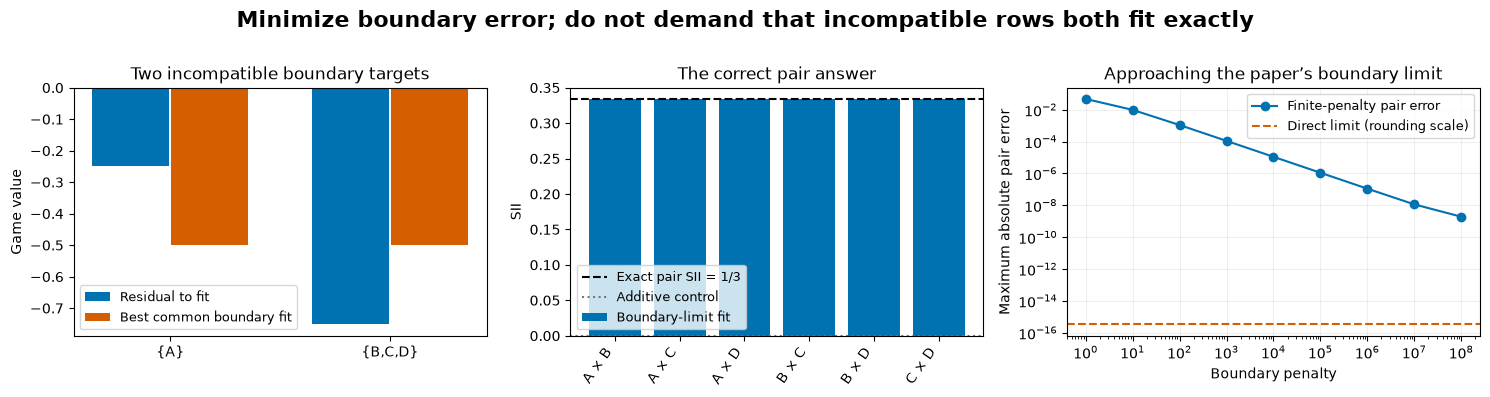

In [14]:
figure = plots.plot_boundary_limit(kernelshap_iq)
show_figure(figure, "04_boundary_limit")

<details>
<summary>Interpretation - what do the finite-penalty curves establish?</summary>

They check the connection with the paper's limit: increasing the boundary weight approaches the same SII answer. They do not promise that larger numerical penalties are always safer. The direct limit avoids an ill-conditioned penalty scale; the rank diagnostic still matters when there are too few sampled interior directions.

</details>

# 4️⃣ Read the real-model comparison

## What is one query in this experiment?

For one held-out Concrete recipe, the game keeps the requested features and takes every absent feature from one intact training recipe. It averages predictions over 64 fixed donors. One coalition query therefore costs 64 underlying predictions; exact enumeration costs 256 coalition queries or 16,384 donor predictions per model/row.

We refit the same seven known predictors from 16.14/16.15 and require all 21 model-state identities to match. The 758 training rows, 153 explanation rows and 119 audit rows are split by recipe groups. Clean seeds, matched shuffled-label seeds and ridge all remain in the comparison.

For this repeated sampling benchmark, we construct the complete model-game oracle once. Each
estimator only receives its queried subset through your `query_sampled_game`. The complete table
and exact SII are available to the evaluator afterward. The figures compare **logical query
budgets**, not measured speedups over direct model calls. The up-front oracle cost is shown, and
it can dominate at eight features.

<details>
<summary>Why keep the exact table outside the estimator?</summary>

The reference must be able to measure all 28 errors even when a method queried only 34 distinct masks. Supplying the complete table directly to the estimator would make that budget meaningless. The query-wrapper tests alter all unqueried values and require both estimates to remain unchanged.

</details>

In [15]:
# Pass your actual completed functions into the fixed native study.
methods = SimpleNamespace(
    coalition_design=coalition_design,
    sii_query_weights=sii_query_weights,
    sample_coalitions=sample_coalitions,
    shapiq_estimate=shapiq_estimate,
    query_sampled_game=query_sampled_game,
    constrained_wls=constrained_wls,
    pair_residual_design=pair_residual_design,
    kernel_weights=kernel_weights,
    kernelshap_iq=kernelshap_iq,
)

In [16]:
# Refit the known models, then run every fixed query plan with your estimators.
# A new output directory preserves each complete run. No fitted cache is supplied.
payload = study.run_study(methods, OUTPUT_DIR / "native")
model_games = payload["games"]
print("All 21 known model-state checks passed.")
print("Complete reference:", model_games["exact_reference_coalition_queries"], "coalition queries;")
print(model_games["exact_reference_donor_predictions"], "underlying donor predictions.")
source_zero = int(t.nonzero(model_games["source_ids"] == 0).item())
display(pd.DataFrame({
    "feature": model_games["feature_names"],
    "source 0 recipe": model_games["queries"][source_zero].numpy(),
    "first intact donor": model_games["donors"][0].numpy(),
}).set_index("feature"))

All 21 known model-state checks passed.
Complete reference: 487424 coalition queries;
31195136 underlying donor predictions.


,source 0 recipe,first intact donor
feature,,
Cement,540.0,318.8
Slag,0.0,212.5
Fly ash,0.0,0.0
Water,162.0,155.7
Superplasticizer,2.5,14.3
Coarse aggregate,1040.0,852.1
Fine aggregate,676.0,880.4
Age,28.0,91.0


## Read model quality before explanation size

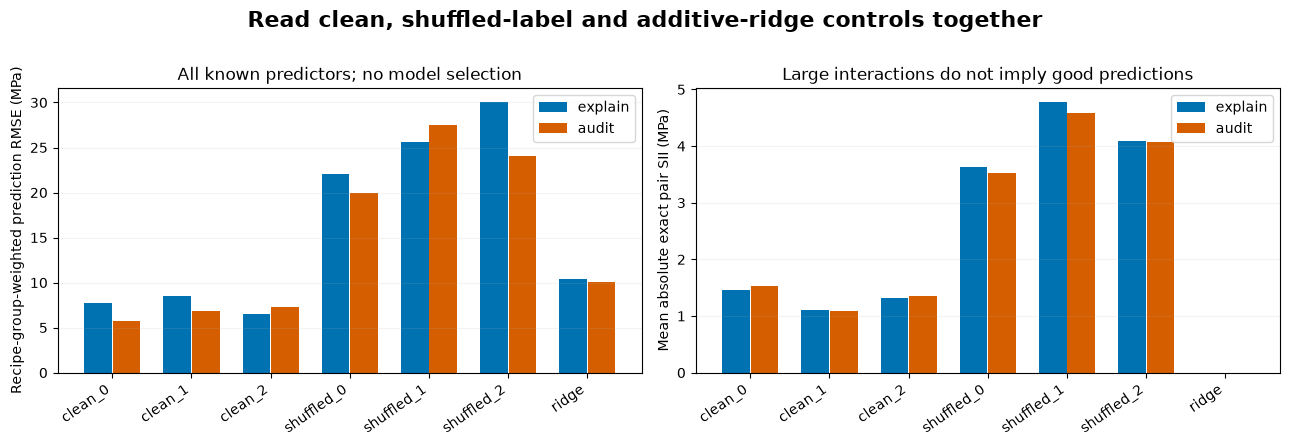

In [17]:
figure = plots.plot_model_controls(payload)
show_figure(figure, "05_model_controls")

The shuffled-label predictors are controls for learning useful predictive structure. They can still have nonzero interactions. Ridge is an additive model and its exact pair SII should be near rounding error. Finite SHAP-IQ may estimate nonzero ridge interactions because its sampled cancellation is imperfect; that is part of the comparison.

## How much error remains at each budget?

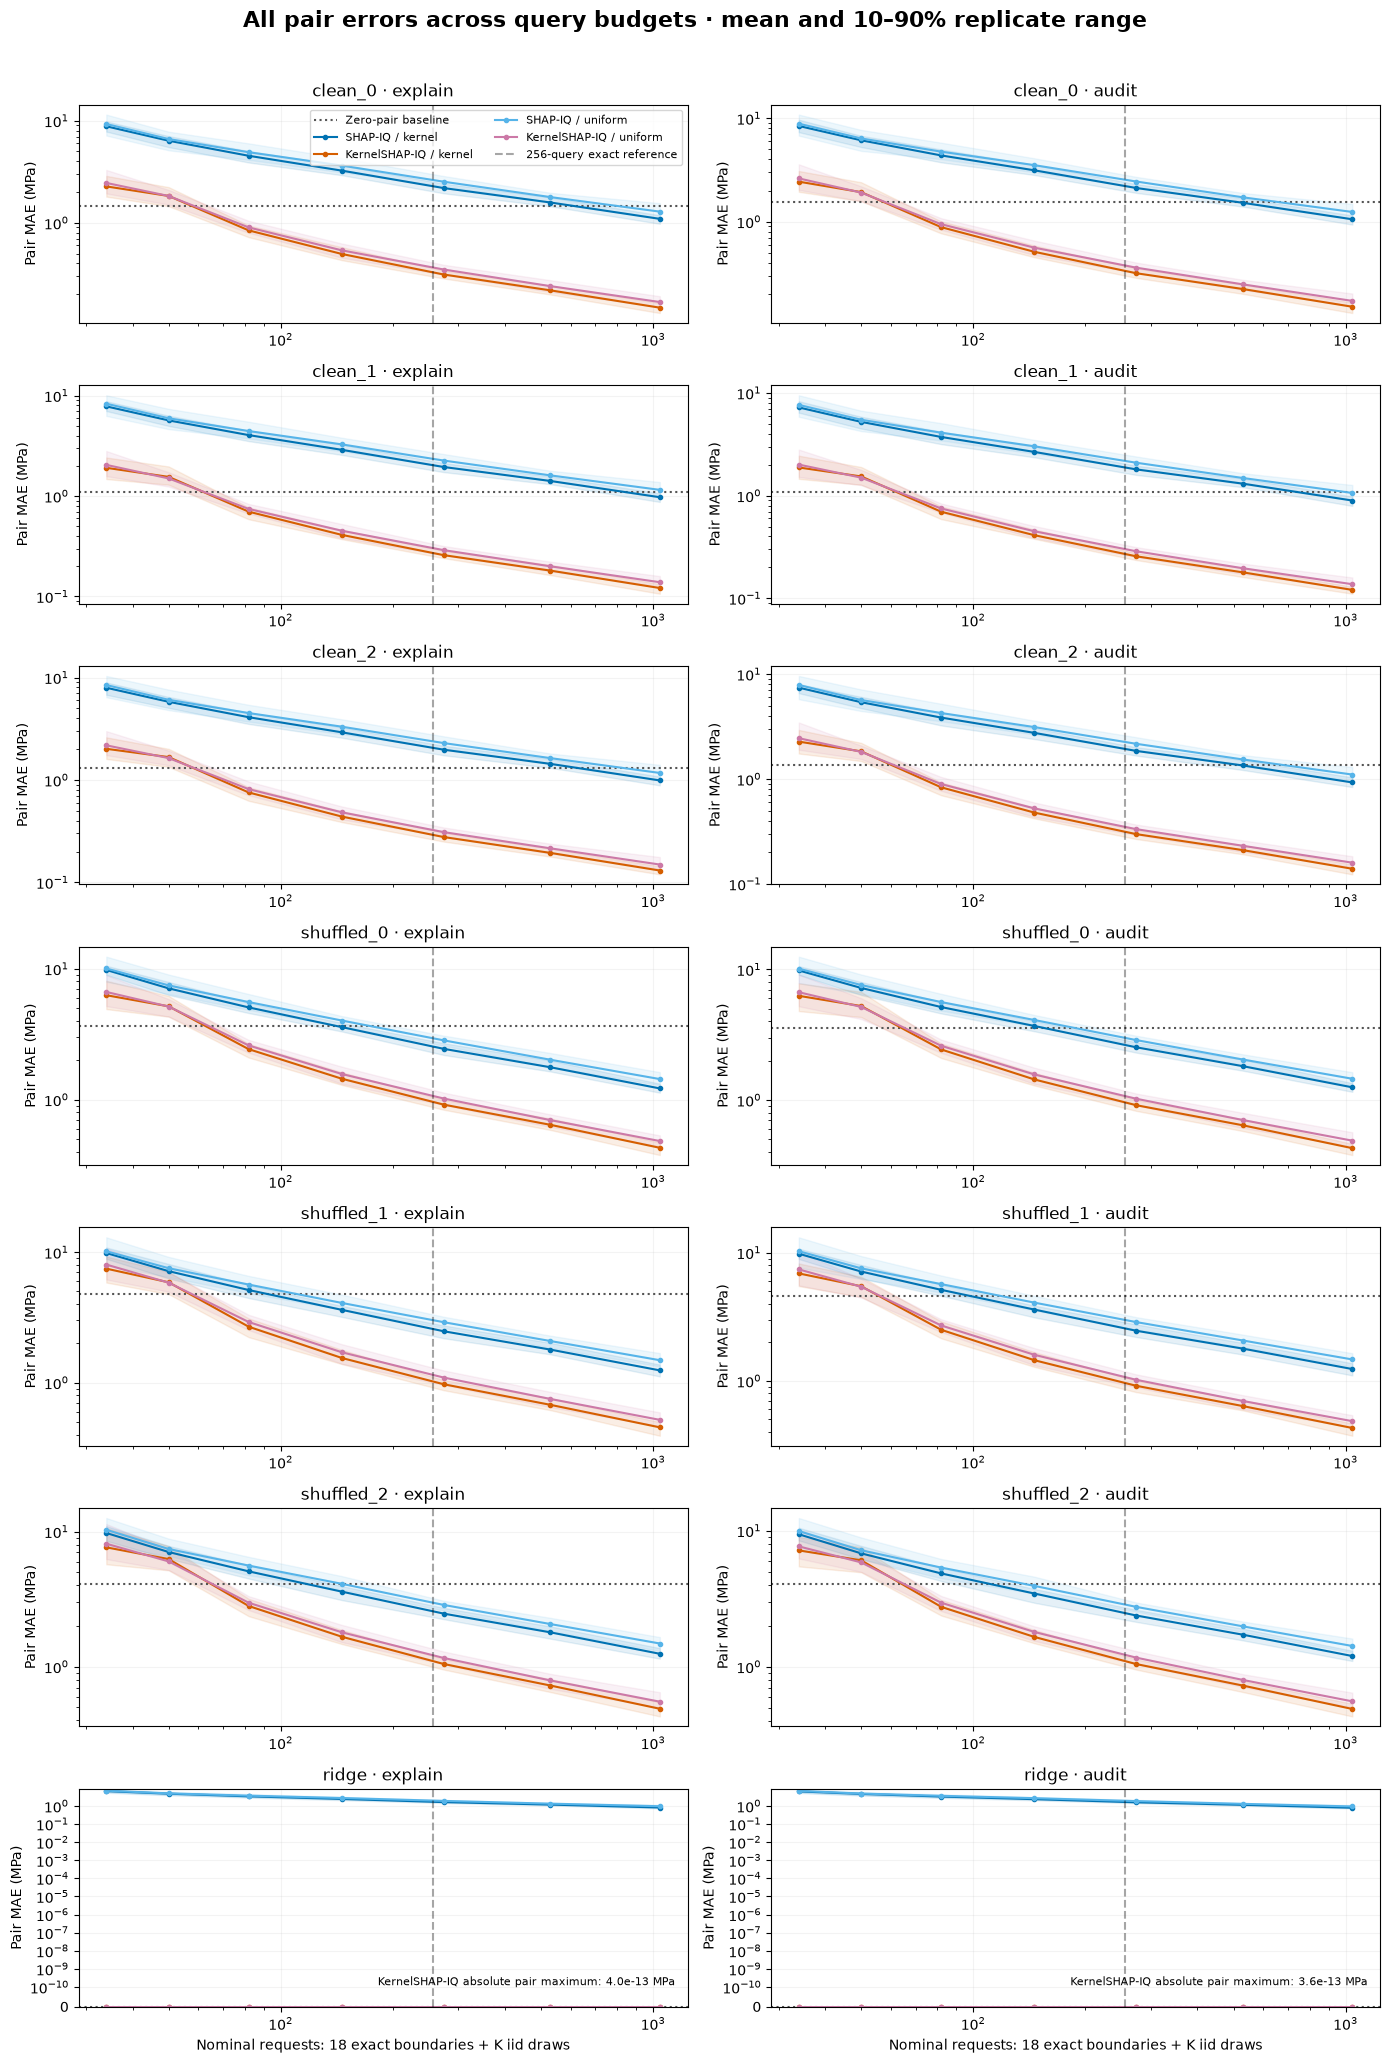

In [18]:
figure = plots.plot_convergence(payload)
show_figure(figure, "06_query_budget_errors")

Every line uses all rows of its indicated held-out split, weighting recipe groups equally before
averaging pair errors. Replicate variation comes from the 32 sampling streams. Those streams are
shared across rows, so rows are not counted as independent Monte Carlo replicates. All model
seeds and both sampling proposals remain visible. The zero-pair baseline shows the error of
doing no interaction estimation at all.

## Signed answers at the fixed recipe

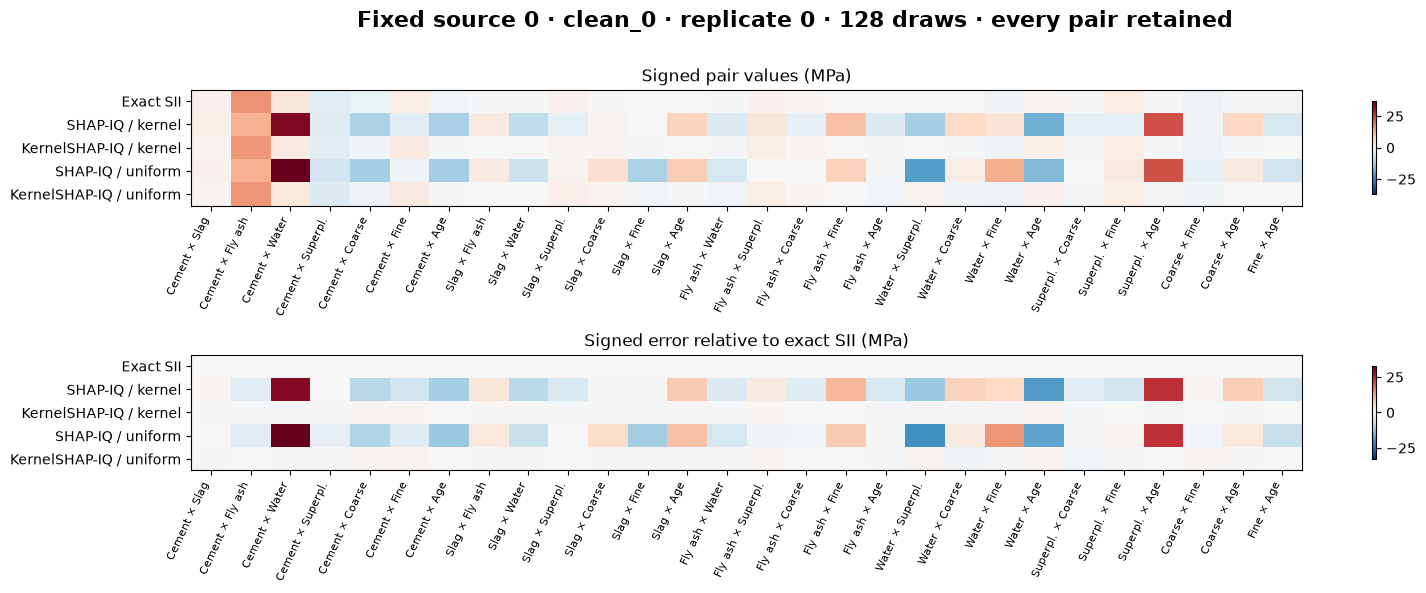

In [19]:
figure = plots.plot_signed_comparison(payload)
show_figure(figure, "07_signed_pair_comparison")

This view fixes the model, source row, replicate and budget before looking at results. Read the signed estimate alongside its error. An accurate mean across many pairs can conceal a wrong sign on one pair, while a single noisy replicate can look much worse than the aggregate curve.

## Does the reported sampling uncertainty mean what we think?

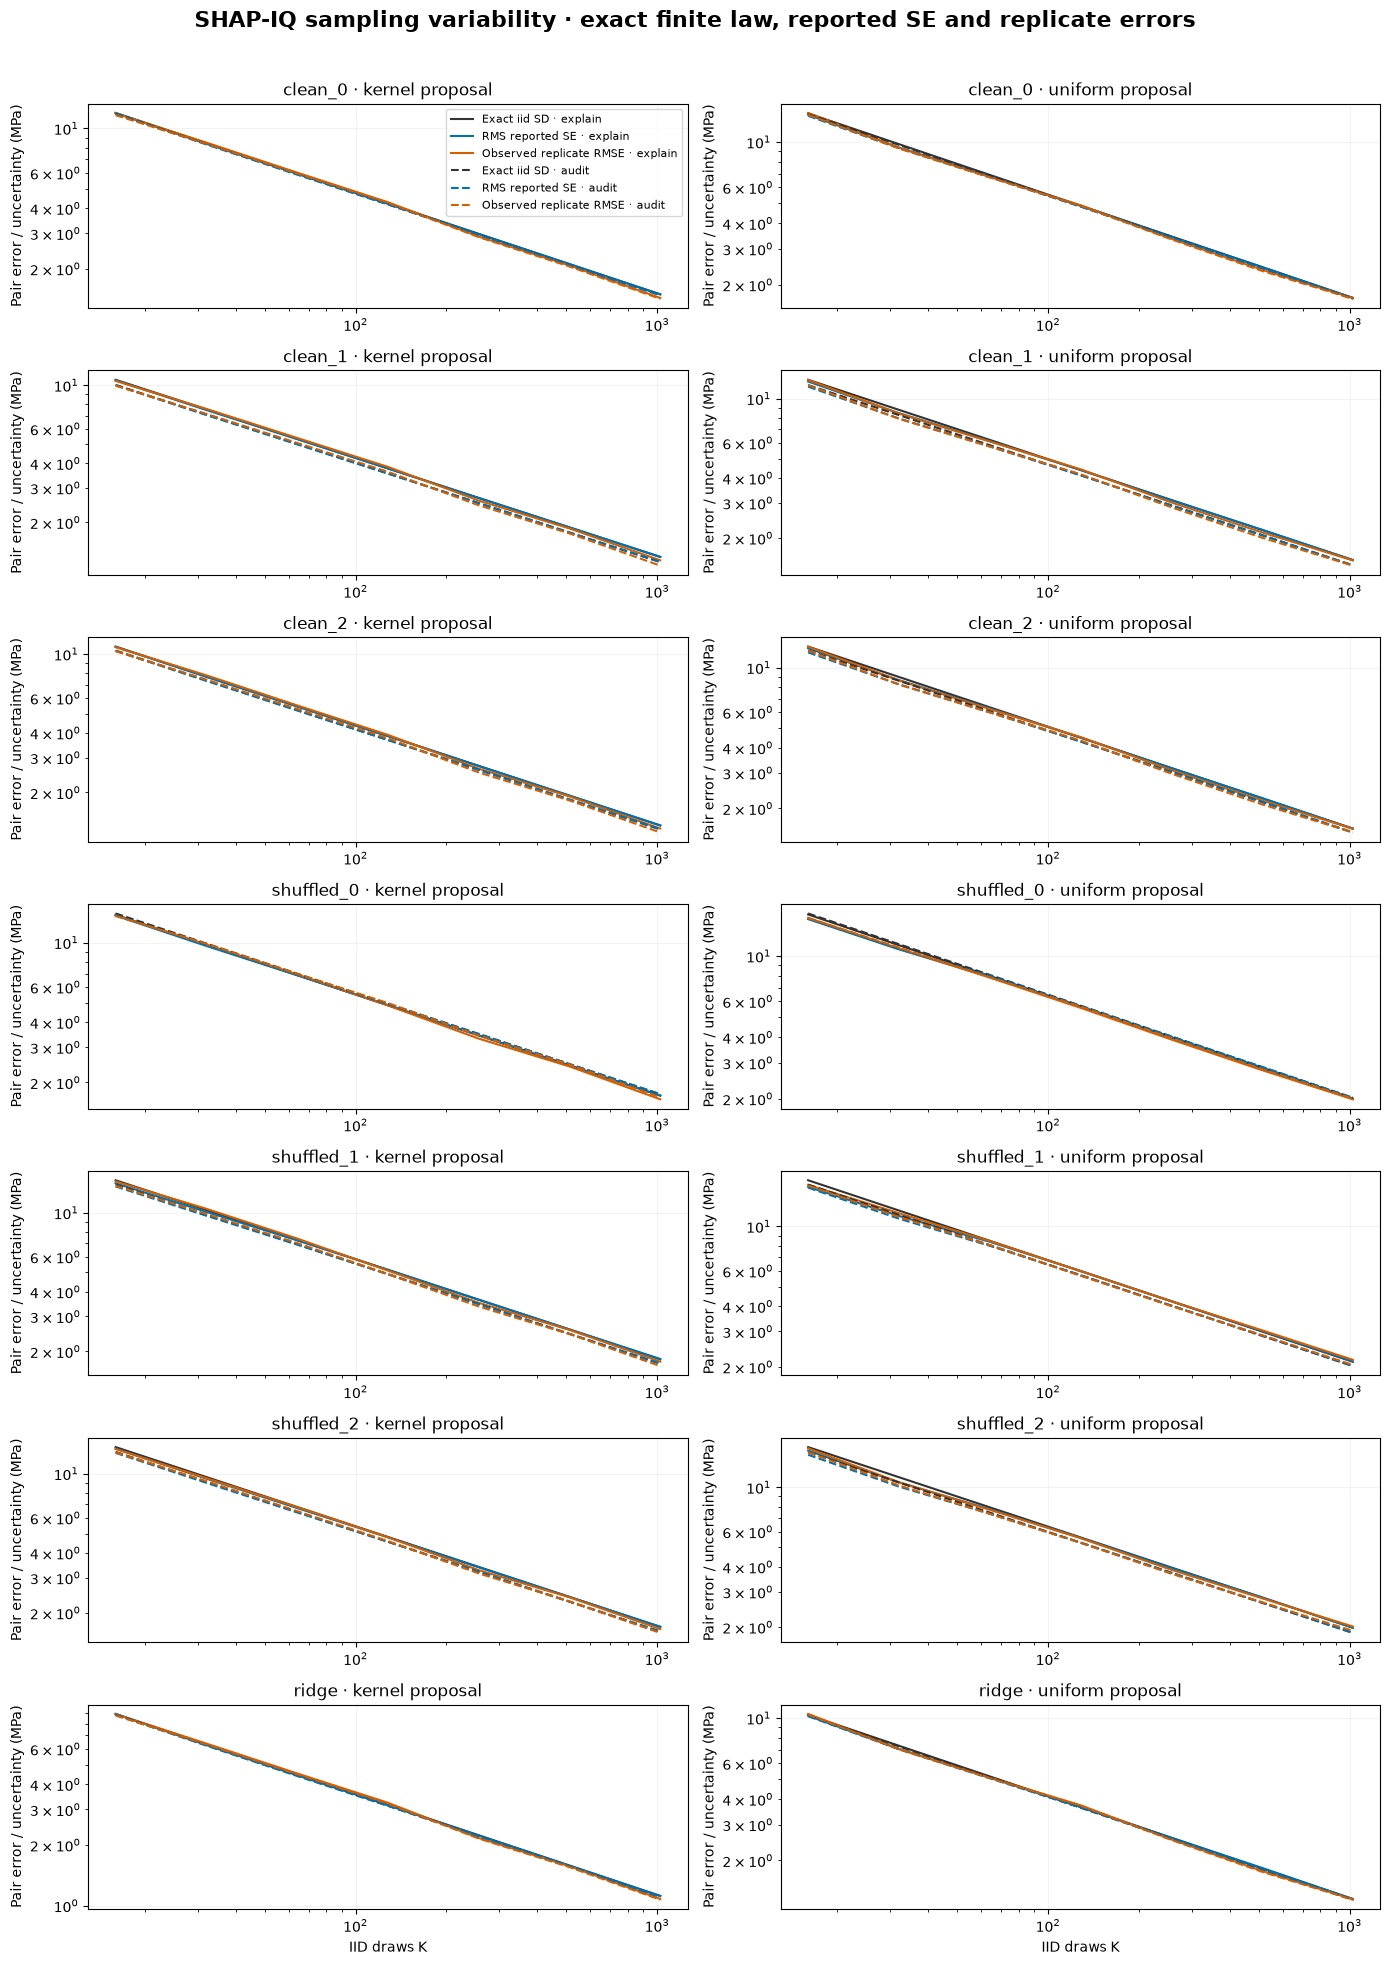

In [20]:
figure = plots.plot_variance(payload)
show_figure(figure, "08_sampling_variance")

Because this game is finite, we can enumerate the exact one-draw variance under each proposal and divide by `K`. Compare that prediction with average estimated SE squared and observed replicate squared errors. Their agreement is a sampling diagnostic. It does not give a confidence interval for concrete chemistry or for future model fits.

## Draws, unique queries and identified directions

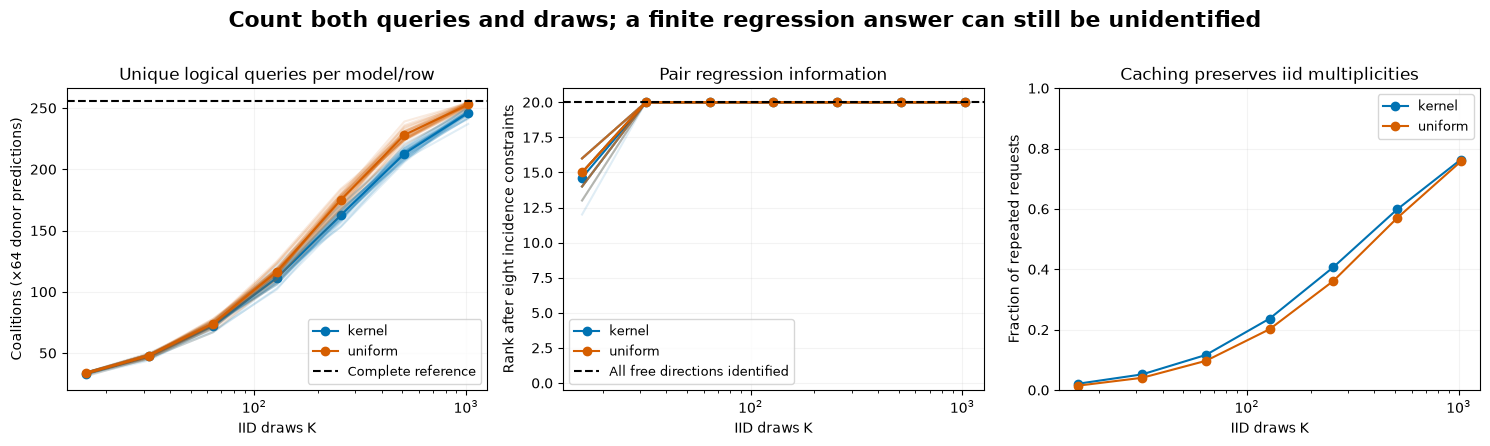

In [21]:
figure = plots.plot_query_costs(payload)
show_figure(figure, "09_unique_queries_and_rank")

Drawing a coalition twice increases the Monte Carlo sample count while the cache pays for its
model evaluation once. Keep both counts. After enough draws, the logical unique-query count
approaches 256; complete enumeration is then a serious alternative. The pair fit has twenty free
directions after its eight incidence constraints. A low-budget estimate can be rank deficient
even if the solver returns a finite coefficient vector.

## Try It Yourself: change the query budget

Change the recipe, model, proposal, seed or number of draws below. Predict which quantity should change: the target SII, the estimate, the reported uncertainty, or the cost. Changing only the seed leaves the target fixed. Changing the recipe or model changes the game. The result is exploratory and does not overwrite the fixed study.

Unique queried masks: [0, 1, 2, 3, 4, 5, 6, 8, 12, 13, 16, 18, 19, 21, 24, 25, 26, 29, 32, 33, 34, 35, 36, 42, 47, 50, 53, 58, 59, 60, 62, 63, 64, 65, 66, 68, 69, 72, 73, 74, 75, 76, 80, 81, 92, 93, 94, 96, 100, 102, 107, 111, 113, 119, 122, 127, 128, 129, 136, 138, 139, 141, 147, 148, 149, 151, 158, 159, 160, 163, 164, 168, 170, 171, 172, 174, 178, 184, 185, 188, 189, 190, 191, 192, 193, 194, 200, 205, 207, 208, 212, 214, 216, 222, 223, 226, 227, 229, 230, 231, 233, 237, 238, 239, 241, 245, 246, 247, 250, 251, 252, 253, 254, 255]
Pair free rank: 20 / 20


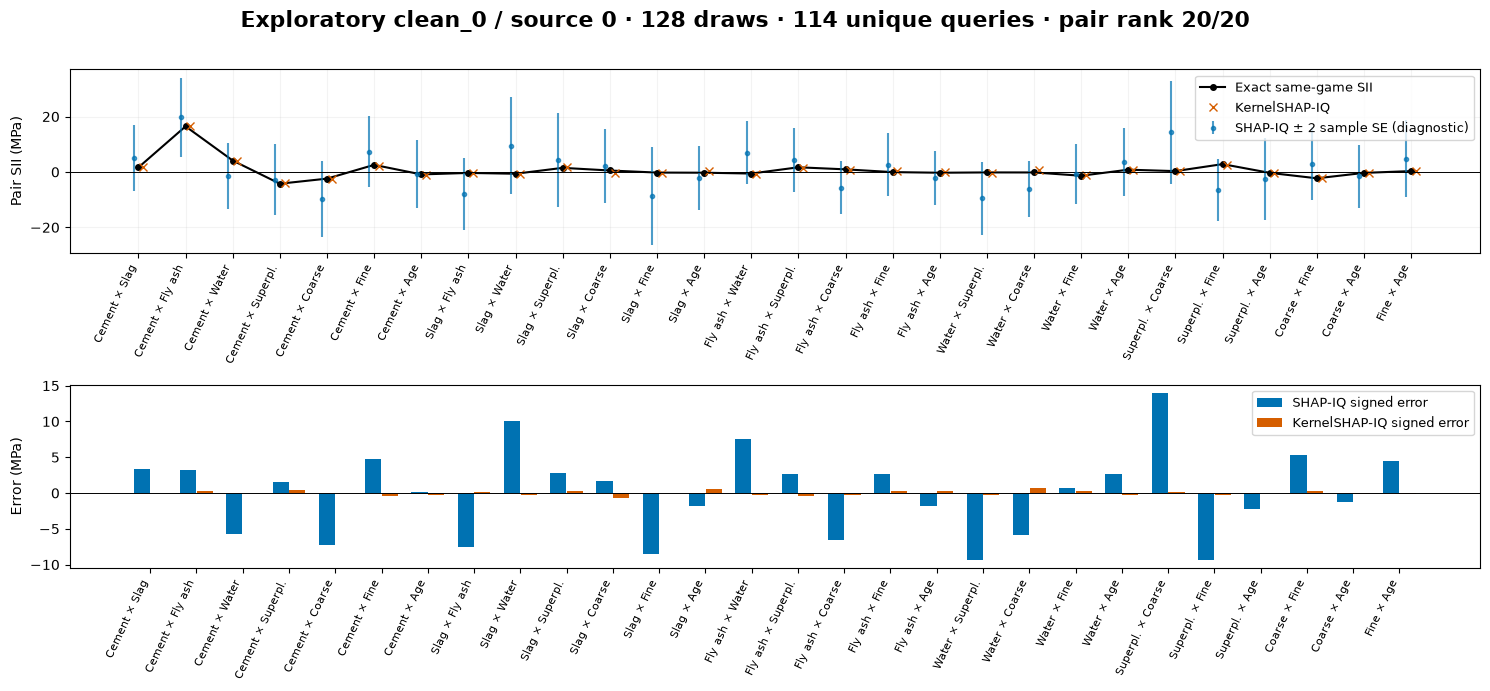

In [22]:
MODEL_KEY = "clean_0"
SOURCE_ID = 0
DRAWS = 128
SEED = 161750
PROPOSAL = "kernel"
play = plots.make_native_play(
    payload, methods, model_key=MODEL_KEY, source_id=SOURCE_ID,
    draws=DRAWS, seed=SEED, proposal=PROPOSAL,
)
print("Unique queried masks:", play["receipt"]["queried_masks"].tolist())
print("Pair free rank:", play["kernelshap_iq"]["pair_stage"]["free_rank"], "/ 20")
if play["exploratory_audit_reuse"]:
    print("Exploratory audit reuse: this play does not change the fixed study.")
figure = plots.plot_native_play(play)
show_figure(figure, "10_native_query_play")

<details>
<summary>Ideas to try</summary>

1. Keep `clean_0` and source row `0`, but switch proposals at the same draw budget. Inspect both the error and unique-query count.
2. Set the model to `ridge`. Compare its exact near-zero pairs with the finite SHAP-IQ error and the KernelSHAP-IQ rank diagnostic.
3. Reduce the budget until the pair fit loses free rank. A finite answer is not the same as an identified regression.
4. Change only the seed and find a case where one pair's sign changes. Compare the two estimates with exact SII before telling a feature-interaction story.

</details>

# Conclusion

One model response can update every pair once we rearrange the SII sum. SHAP-IQ estimates that shared sum directly; KernelSHAP-IQ fits main effects and pair residuals to the same queries. They can differ at a finite budget while targeting the same exact interaction index.

You have also seen three distinct limits: finite sampling leaves noise, incomplete designs leave unidentified directions, and an exact interaction remains a property of a chosen fitted model and replacement game. The eight-feature experiment makes those limits measurable. It does not establish large-feature scalability or physical causal interactions.

## Further reading

- [SHAP-IQ: Unified Approximation of any-order Shapley Interactions](https://proceedings.neurips.cc/paper_files/paper/2023/file/264f2e10479c9370972847e96107db7f-Paper-Conference.pdf), especially the shared-query representation and iid estimator in Section 4.
- [KernelSHAP-IQ: Weighted Least Square Optimization for Shapley Interactions](https://proceedings.mlr.press/v235/fumagalli24a.html), especially the pairwise theorem and sequential algorithm. The higher-order WLS results include conjectures; this lesson uses the proved pairwise case.
- Section 16.3 for the discrete-derivative SII definition; 16.16 for changing the allocation rule instead of approximating a fixed one.
- Sections 16.14–16.15 for the known Concrete model/data recipe and finite-donor interpretation.